# Estimación de niveles de obesidad (UCI 544) — EDA, selección de variables, modelos y Optuna

**Grupo 2 — Integrantes y aportes**

- **Estrada Cordero, Diago Nicolas:** carga de datos, clasificación de variables, análisis exploratorio, análisis del IMC por clase y prueba de fuga de información.
- **García Bautista, Diego Sebastián:** correlación, separación entrenamiento/prueba, preprocesamiento, selección de variables y modelo KNN con Optuna.
- **Ramírez Quiroz, Marco Jesús:** configuración del cuaderno, `Pipeline`, función de evaluación, modelos de referencia y ejecución de los escenarios A y B.
- **Terán Linares, Julio César:** funciones de Optuna, XGBoost con Optuna y comparación final de modelos.

**Uso de IA en el código:** se usó un asistente de IA (Claude) para revisar el cuaderno ya terminado, no para escribirlo desde cero.

> `# PROMPT usado: "Revisa las funcionalidades de nuestro proyecto universitario de machine learning y que los pasos sigan la secuencia correcta, y recomiéndanos mejoras. Solo busca mejoras siguiendo el mismo patrón y los temas que ya usamos; no extiendas el trabajo ni agregues temas que no hemos visto en el curso."`

Cambios que salieron de esa revisión: quitar la sección de Boruta (tenía fuga de información y no se usaba) y la sección 4.1 repetida, entrenar la MLP sin `early_stopping` (se detenía antes de converger), función `registrar` sin filas duplicadas, interpretación de outliers en variables discretas y limpieza de textos.

---

## Cómo está armado este cuaderno

1. **EDA:** faltantes, duplicados, distribución de clases, variables de encuesta con decimales (efecto de SMOTE), outliers y evidencia de que la etiqueta se calcula con el IMC.
2. **Separación** en entrenamiento y prueba **antes** de cualquier ajuste. Escalado, codificación y selección de variables van dentro de un `Pipeline`.
3. **Dos escenarios**, porque la etiqueta se calcula a partir de `Weight` y `Height` (fuga de información):
   - **A:** con todas las variables.
   - **B:** sin `Weight` ni `Height` (el modelo debe aprender de los hábitos).
4. **Modelos:**
   - *Referencia:* regresión logística, árbol de decisión, Naive Bayes, Random Forest, SVM y MLP.
   - *Propuestos:* **XGBoost** y **KNN**, optimizados con **Optuna**. Los autores del dataset no los usaron (De-La-Hoz-Correa et al., 2019 trabajan con árboles de decisión); XGBoost sí aparece en Gozukara Bag et al. (2023), pero sin separar el efecto del IMC.
5. **Comparación final** de todos los modelos en ambos escenarios.

In [ ]:
!pip install -q optuna xgboost

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

SEED = 42   # semilla fija para que los resultados sean reproducibles (el valor es arbitrario)

URL = "https://raw.githubusercontent.com/20232405-cloud/Estimaci-n-de-los-niveles-de-obesidad-basada-en-los-h-bitos-alimenticios-y-la-condici-n-f-sica/refs/heads/main/ObesityDataSet_raw_and_data_sinthetic.csv"

## 1. Carga de datos y definición de columnas

In [ ]:
df = pd.read_csv(URL)
df.columns = [c.strip() for c in df.columns]
print(df.shape)    # esperado: (2111, 17)
df.head()

(2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [ ]:
# FCVC, NCP, CH2O, FAF y TUE son respuestas de encuesta con pocas opciones (valores enteros).
# SMOTE las convirtió en decimales al interpolar; se redondean al entero más cercano
# (recomendación del docente). Ver la explicación en la sección 2.3.
columnas_discretas_smote = ["FCVC", "NCP", "CH2O", "FAF", "TUE"]

print("Valores antes del redondeo (primeras filas):")
display(df[columnas_discretas_smote].head())

for col in columnas_discretas_smote:
    df[col] = df[col].round().astype(int)

print("\nValores después del redondeo:")
display(df[columnas_discretas_smote].head())

Valores antes del redondeo (primeras filas):


,FCVC,NCP,CH2O,FAF,TUE
0,2.0,3.0,2.0,0.0,1.0
1,3.0,3.0,3.0,3.0,0.0
2,2.0,3.0,2.0,2.0,1.0
3,3.0,3.0,2.0,2.0,0.0
4,2.0,1.0,2.0,0.0,0.0



Valores después del redondeo:


,FCVC,NCP,CH2O,FAF,TUE
0,2,3,2,0,1
1,3,3,3,3,0
2,2,3,2,2,1
3,3,3,2,2,0
4,2,1,2,0,0


In [ ]:
TARGET = "NObeyesdad"

# Orden natural de las clases (de menor a mayor peso). No se usa el orden alfabético.
ORDEN_CLASES = ["Insufficient_Weight", "Normal_Weight", "Overweight_Level_I", "Overweight_Level_II",
                "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"]

binarias  = ["Gender", "family_history_with_overweight", "FAVC", "SMOKE", "SCC"]   # dos categorías (texto)
ordinales = ["CAEC", "CALC"]                                                       # no < Sometimes < Frequently < Always
nominales = ["MTRANS"]                                                             # medio de transporte (sin orden)
numericas = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"]

definidas = set(binarias + ordinales + nominales + numericas + [TARGET])
#Todas las columnas fueron asignadas del csv
print("En el CSV pero no en mis listas:", set(df.columns) - definidas)
# Todas las columnas de las listas existen en el CSV (sin errores de escritura)
print("En mis listas pero no en el CSV:", definidas - set(df.columns))
# Medidas de seguridad para no arrastrar errores al pipeline
assert definidas == set(df.columns), "Revisar los nombres de columnas"
assert set(df[TARGET].unique()) == set(ORDEN_CLASES), "Clases inesperadas en el objetivo"

En el CSV pero no en mis listas: set()
En mis listas pero no en el CSV: set()


## 2. Análisis exploratorio (EDA)

### 2.1 Variable objetivo

                     Cantidad  Porcentaje
NObeyesdad                               
Insufficient_Weight       272       12.88
Normal_Weight             287       13.60
Overweight_Level_I        290       13.74
Overweight_Level_II       290       13.74
Obesity_Type_I            351       16.63
Obesity_Type_II           297       14.07
Obesity_Type_III          324       15.35


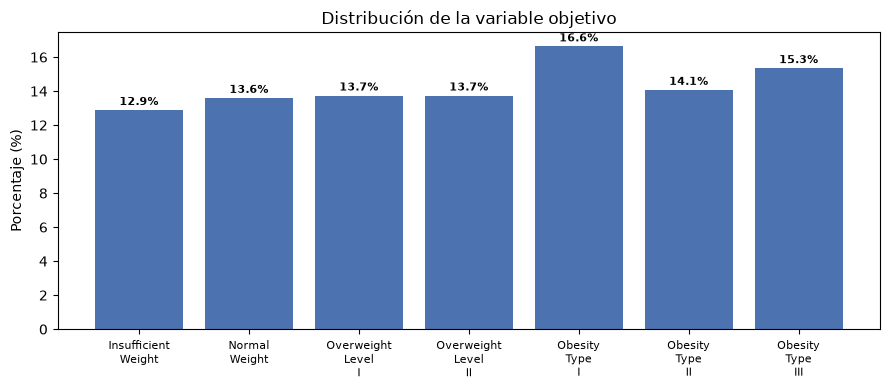

In [ ]:

#Ordenamos de menor a mayor con reindex
#Al codificar las etiquetas como números (0, 1, 2, 3, 4, 5, 6)
dist = df[TARGET].value_counts().reindex(ORDEN_CLASES)

#Calcular porcentaje
pct = dist / len(df) * 100
print(pd.DataFrame({"Cantidad": dist, "Porcentaje": pct.round(2)}))

#Grafica
plt.figure(figsize=(9, 4))
plt.bar(range(len(pct)), pct.values, color="#4c72b0")
plt.xticks(range(len(pct)), [c.replace("_", "\n") for c in pct.index], fontsize=8)
for i, v in enumerate(pct.values):
    plt.text(i, v + 0.3, f"{v:.1f}%", ha="center", fontsize=8, fontweight="bold")
plt.ylabel("Porcentaje (%)"); plt.title("Distribución de la variable objetivo")
plt.tight_layout(); plt.show()

**Interpretación:** las siete clases están casi balanceadas (entre 12.9 % y 16.6 %). Esto no es natural: los autores ya aplicaron SMOTE para balancear y el 77 % de los registros es sintético. Por eso no se aplica otra técnica de balanceo.

### 2.2 Faltantes y duplicados

In [ ]:
print("Valores nulos totales:", int(df.isna().sum().sum()))
n_dup = int(df.duplicated().sum())
print("Filas duplicadas:", n_dup)

# Decisión: se eliminan los duplicados exactos ANTES de separar los datos, porque una fila idéntica
# podría quedar en entrenamiento y en prueba a la vez e inflar las métricas.
if n_dup > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Nuevo tamaño:", df.shape)

Valores nulos totales: 0
Filas duplicadas: 24
Nuevo tamaño: (2087, 17)


### 2.3 Variables de encuesta con decimales

`FCVC`, `NCP`, `CH2O`, `FAF` y `TUE` son respuestas de encuesta con pocas opciones (por ejemplo "nunca / a veces / siempre"). En el CSV original aparecen con decimales porque SMOTE genera registros nuevos interpolando entre vecinos reales. La tabla confirma que, después del redondeo de la sección 1, ya no quedan decimales.

In [ ]:
# Verificación de decimales tras la aplicación del redondeo
discretas = ["FCVC", "NCP", "CH2O", "FAF", "TUE"]
tabla_dec = pd.DataFrame({
    "Valores únicos": [df[c].nunique() for c in discretas],
    "Filas con decimales": [int((df[c] != df[c].round()).sum()) for c in discretas],
    "Porcentaje con decimales": [round((df[c] != df[c].round()).mean() * 100, 1) for c in discretas],
}, index=discretas)

print("Verificación de decimales después de aplicar la corrección:")
display(tabla_dec)

Verificación de decimales después de aplicar la corrección:


,Valores únicos,Filas con decimales,Porcentaje con decimales
FCVC,3,0,0.0
NCP,4,0,0.0
CH2O,3,0,0.0
FAF,4,0,0.0
TUE,3,0,0.0


**Decisión (recomendación del docente):** se redondean `FCVC`, `NCP`, `CH2O`, `FAF` y `TUE` al entero más cercano, porque un valor como 2.37 no es una respuesta posible en la encuesta. Así las variables vuelven a su escala original.

### 2.4 Outliers (IQR y Z-score)

,Variable,Límite inferior,Límite superior,Outliers,Porcentaje
0,CH2O,2.00,2.00,980,46.96
1,NCP,3.00,3.00,621,29.76
2,Age,10.79,35.13,167,8.00
3,Height,1.42,1.98,1,0.05
4,Weight,2.98,171.04,1,0.05
5,FCVC,0.50,4.50,0,0.00
6,FAF,-3.00,5.00,0,0.00
7,TUE,-1.50,2.50,0,0.00


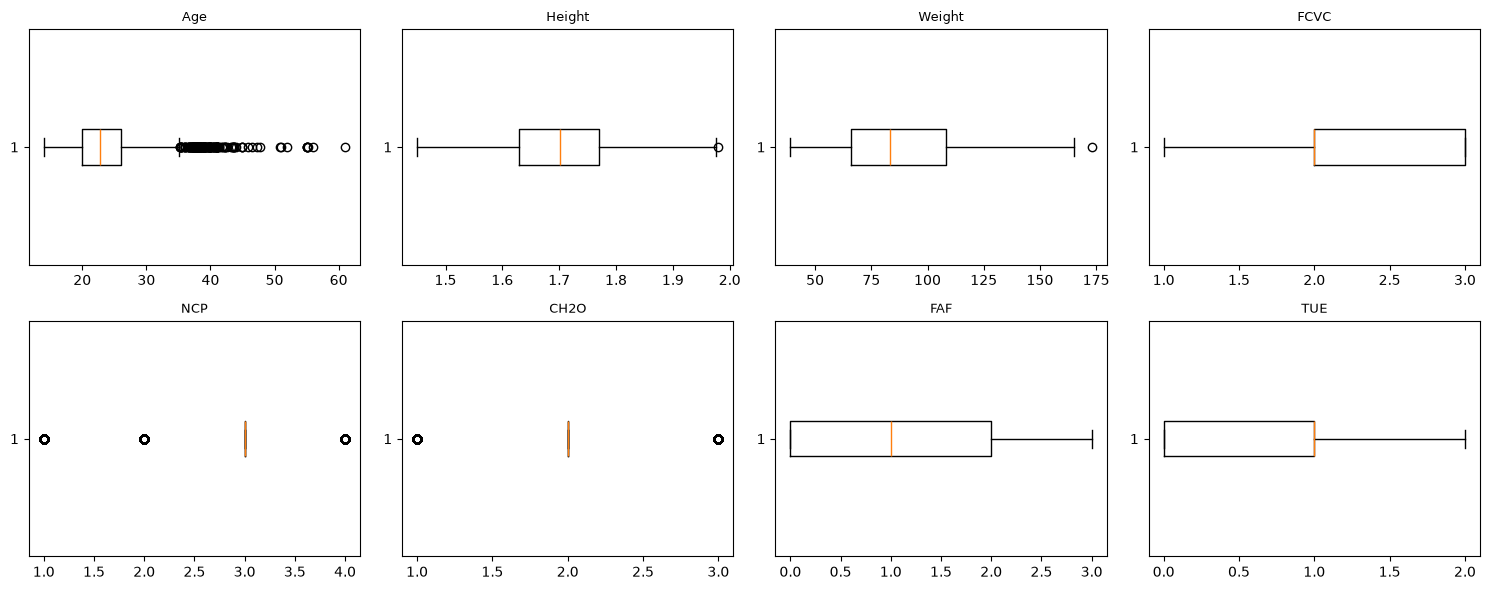

In [ ]:
def resumen_outliers_iqr(data, variables):
    filas = []
    for v in variables:
        q1, q3 = data[v].quantile(0.25), data[v].quantile(0.75)
        iqr = q3 - q1
        inf, sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n = int(((data[v] < inf) | (data[v] > sup)).sum())
        filas.append({"Variable": v, "Límite inferior": round(inf, 2), "Límite superior": round(sup, 2),
                      "Outliers": n, "Porcentaje": round(n / len(data) * 100, 2)})
    return pd.DataFrame(filas).sort_values("Outliers", ascending=False).reset_index(drop=True)

display(resumen_outliers_iqr(df, numericas))

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, v in zip(axes.ravel(), numericas):
    ax.boxplot(df[v], vert=False); ax.set_title(v, fontsize=9)
plt.tight_layout(); plt.show()

Como contraste se usa el **Z-score**: se considera outlier a toda observación con |Z| > 3 (en una distribución normal, solo el 0.27 % más extremo).

In [ ]:
from scipy import stats

def resumen_outliers_zscore(data, variables, umbral=3):
    filas = []
    for v in variables:
        # Calculamos el Z-score para la variable
        z_scores = np.abs(stats.zscore(data[v]))
        n = int((z_scores > umbral).sum())
        filas.append({
            "Variable": v,
            "Outliers (Z > 3)": n,
            "Porcentaje (Z)": round(n / len(data) * 100, 2)
        })
    return pd.DataFrame(filas).sort_values("Outliers (Z > 3)", ascending=False).reset_index(drop=True)

# Comparación de ambos métodos
tabla_iqr = resumen_outliers_iqr(df, numericas)[["Variable", "Outliers", "Porcentaje"]].rename(
    columns={"Outliers": "Outliers (IQR)", "Porcentaje": "Porcentaje (IQR)"}
)
tabla_z = resumen_outliers_zscore(df, numericas)

comparativa_outliers = pd.merge(tabla_iqr, tabla_z, on="Variable")
display(comparativa_outliers)

,Variable,Outliers (IQR),Porcentaje (IQR),Outliers (Z > 3),Porcentaje (Z)
0,CH2O,980,46.96,0,0.00
1,NCP,621,29.76,0,0.00
2,Age,167,8.00,23,1.10
3,Height,1,0.05,0,0.00
4,Weight,1,0.05,1,0.05
5,FCVC,0,0.00,0,0.00
6,FAF,0,0.00,0,0.00
7,TUE,0,0.00,0,0.00


**Interpretación:** con IQR, `CH2O` y `NCP` aparecen con muchos "outliers" (47 % y 30 %), pero no son errores: después del redondeo casi todos responden 2 vasos de agua o 3 comidas, así que el rango intercuartílico es 0 y cualquier otra respuesta queda fuera. En variables discretas el IQR no es útil; el Z-score no marca ninguno. En las continuas, `Age` tiene 167 outliers por IQR (23 por Z-score), que son personas mayores reales, y `Weight` y `Height` solo uno cada una. No se elimina ningún registro.

### 2.5 Correlación entre variables numéricas

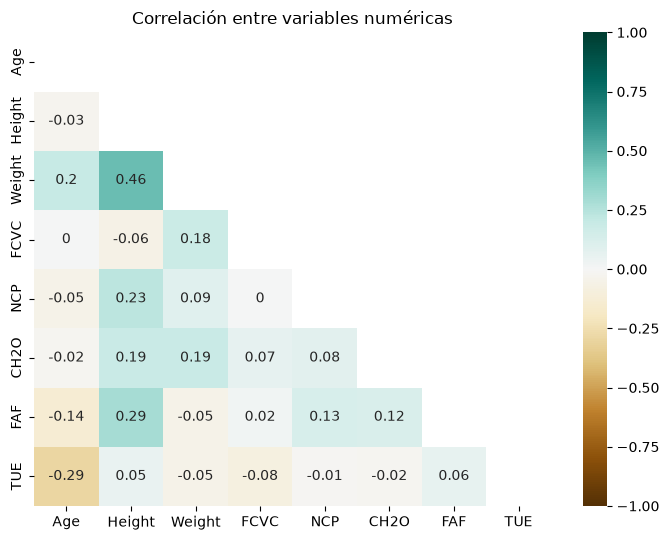

In [ ]:
corr_total = df[numericas].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_total.round(2), mask=np.triu(np.ones_like(corr_total, dtype=bool)),
            cmap="BrBG", vmin=-1, vmax=1, annot=True)
plt.title("Correlación entre variables numéricas"); plt.tight_layout(); plt.show()

### 2.6 Evidencia de fuga de información: la etiqueta sale del IMC

Según el paper del dataset, la clase se calculó con el IMC = peso / altura² y los umbrales de la OMS. Si es así, el IMC (calculado a partir de `Weight` y `Height`) debería separar casi perfectamente las clases.

,min,mean,max
NObeyesdad,,,
Insufficient_Weight,13.0,17.4,19.1
Normal_Weight,18.5,22.0,24.9
Overweight_Level_I,22.8,26.0,28.8
Overweight_Level_II,25.7,28.2,30.4
Obesity_Type_I,29.9,32.3,35.2
Obesity_Type_II,34.0,36.7,39.8
Obesity_Type_III,36.8,42.3,50.8


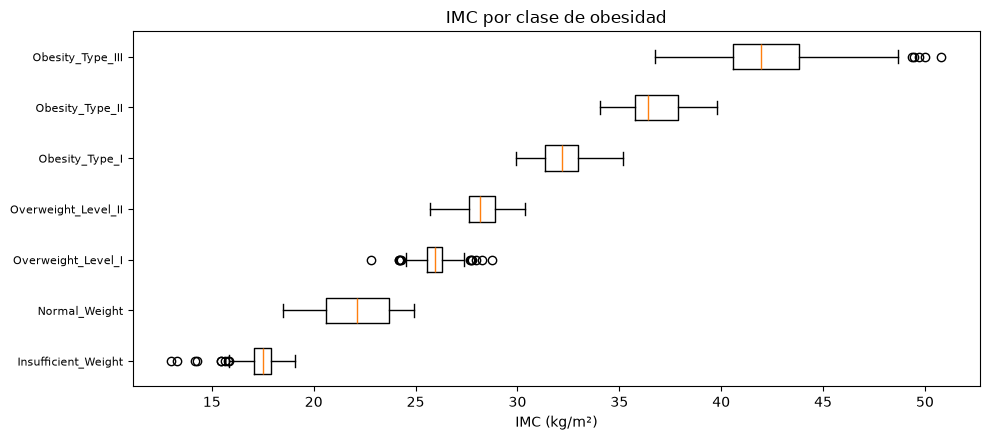

In [ ]:
df_imc = df.copy()
df_imc["IMC"] = df_imc["Weight"] / df_imc["Height"] ** 2

resumen_imc = df_imc.groupby(TARGET)["IMC"].agg(["min", "mean", "max"]).reindex(ORDEN_CLASES).round(1)
display(resumen_imc)

plt.figure(figsize=(10, 4.5))
plt.boxplot([df_imc.loc[df_imc[TARGET] == c, "IMC"] for c in ORDEN_CLASES], vert=False)
plt.yticks(range(1, 8), ORDEN_CLASES, fontsize=8)
plt.xlabel("IMC (kg/m²)"); plt.title("IMC por clase de obesidad")
plt.tight_layout(); plt.show()

**Interpretación:** cada clase ocupa un rango propio de IMC y los rangos casi no se solapan, solo en los bordes entre clases vecinas. Un modelo que recibe `Weight` y `Height` puede reconstruir la etiqueta sin aprender nada de los hábitos. Por eso se definen los escenarios A y B.

## 3. Separación en entrenamiento y prueba

Se hace **antes** de cualquier ajuste, con `stratify` para mantener la proporción de clases. La validación se hace con **validación cruzada sobre el entrenamiento**; el conjunto de prueba se usa **una sola vez al final**. El objetivo se codifica con el **orden natural** de las clases (no alfabético).

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

X = df.drop(columns=[TARGET])
assert TARGET not in X.columns          # el objetivo NO puede estar en X

mapa = {c: i for i, c in enumerate(ORDEN_CLASES)}
y = df[TARGET].map(mapa).values
CLASES = ORDEN_CLASES
#tanto el conjunto de entrenamiento como el de prueba mantengan exactamente la misma proporción de clases de obesidad que el dataset original.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

#Hiperparametros y validacion cruzada evitar  "memorizarlos" (overfitting).
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

Entrenamiento: (1669, 16) | Prueba: (418, 16)


In [ ]:
# Prueba de la fuga: un árbol pequeño que recibe SOLO el IMC (validación cruzada en entrenamiento)
#95% de accuracy (0.950) significa que de cada 100 registros evaluados,
# el árbol de decisión clasificó correctamente el nivel de obesidad de 95 personas.
from sklearn.tree import DecisionTreeClassifier

imc_train = (X_train["Weight"] / X_train["Height"] ** 2).to_frame("IMC")
acc_imc = cross_val_score(DecisionTreeClassifier(max_depth=4, random_state=SEED), imc_train, y_train,
                          cv=cv5, scoring="accuracy")
print(f"Accuracy de un árbol (profundidad 4) usando solo el IMC: {acc_imc.mean():.3f}")

Accuracy de un árbol (profundidad 4) usando solo el IMC: 0.950


**Interpretación:** con una sola variable (el IMC) un árbol muy pequeño acierta en el 95 % de los casos. Eso confirma la fuga de información: en el escenario A las métricas altas se deben a la fórmula del IMC y no a los hábitos.

## 4. Pipeline, selección de variables y utilidades

- **Codificación:** variables binarias → 0/1; `CAEC` y `CALC` → ordinal (no < Sometimes < Frequently < Always); `MTRANS` → one-hot; numéricas → estandarizadas.
- **Selección de variables (solo con entrenamiento):** (1) filtro por correlación |r| > 0.90 entre numéricas; (2) importancia con Random Forest, aplicada dentro del `Pipeline` con `SelectFromModel` para que se recalcule en cada fold. Se comparan tres configuraciones (sin selección, conservadora y agresiva) con validación cruzada y se elige la mejor.
- **Balanceo:** no se aplica, porque las clases ya están casi equilibradas.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix, classification_report

ORD_CATS = [["no", "Sometimes", "Frequently", "Always"]] * len(ordinales)

def construir_cfg(excluir=()):
    return {"num": [c for c in numericas if c not in excluir]}

def filtro_correlacion(num, umbral=0.90):
    corr = X_train[num].corr().abs()
    sup = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    return [c for c in sup.columns if (sup[c] > umbral).any()]

def crear_preprocesador(cfg):
    return ColumnTransformer([
        ("num", StandardScaler(), cfg["num"]),
        ("bin", OneHotEncoder(drop="if_binary", sparse_output=False), binarias),
        ("ord", Pipeline([("o", OrdinalEncoder(categories=ORD_CATS, handle_unknown="use_encoded_value", unknown_value=-1)),
                          ("s", StandardScaler())]), ordinales),
        ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominales),
    ])

def crear_pipeline(clf, cfg, seleccion):
    """seleccion: None (sin selección) o el umbral de SelectFromModel, p. ej. 'median' o '0.5*median'."""
    pasos = [("prep", crear_preprocesador(cfg))]
    if seleccion:
        pasos.append(("sel", SelectFromModel(
            RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1), threshold=seleccion)))
    pasos.append(("clf", clf))
    return Pipeline(pasos)

def cv_f1(pipe, cv=cv5):
    r = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    return r.mean(), r.std()

resultados = []       # una fila por modelo y escenario (tabla final)
predicciones = {}     # para matrices de confusión

def registrar(escenario, nombre, origen, pipe):
    """Ajusta con TODO el entrenamiento y evalúa UNA vez en prueba."""
    # Si la celda se vuelve a ejecutar, se reemplaza la fila anterior en vez de duplicarla
    resultados[:] = [r for r in resultados if not (r["Escenario"] == escenario and r["Modelo"] == nombre)]
    f1_cv, _ = cv_f1(pipe)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    errores = pred != y_test
    adyacentes = (np.abs(pred.astype(int) - y_test.astype(int)) == 1) & errores
    fila = {
        "Escenario": escenario, "Modelo": nombre, "Origen": origen,
        "F1 macro (CV)": round(f1_cv, 4),
        "Accuracy (prueba)": round(accuracy_score(y_test, pred), 4),
        "F1 macro (prueba)": round(f1_score(y_test, pred, average="macro"), 4),
        "Recall macro (prueba)": round(recall_score(y_test, pred, average="macro"), 4),
        "% errores a clase vecina": round(adyacentes.sum() / max(errores.sum(), 1) * 100, 1),
    }
    predicciones[(escenario, nombre)] = pred
    resultados.append(fila)
    return pipe

## 5. Modelos y Optuna

Las funciones de abajo se ejecutan **una vez por escenario** (sección 6). En cada escenario se muestra la importancia de variables con Random Forest y se comparan tres configuraciones de `SelectFromModel`.

- **Referencia:** regresión logística, árbol de decisión (criterio de entropía, parecido a J48), Naive Bayes, Random Forest, SVM y MLP.
- **Propuestos:** **XGBoost** (boosting de árboles: construye árboles en secuencia corrigiendo los errores del anterior) y **KNN** (clasifica por cercanía a los vecinos, basado en distancias).
- **Optuna:** busca la combinación de hiperparámetros que maximiza el F1 macro en validación cruzada (3 particiones) sobre el entrenamiento, con 30 pruebas por modelo. El conjunto de prueba no interviene.

> **Nota sobre la MLP:** no se usa `early_stopping`. Con tan pocos datos, esa opción separa un 10 % para validar y detiene el entrenamiento demasiado pronto: el F1 en validación cruzada quedaba en ~0.66 con mucha variación entre particiones. Sin ella y con `max_iter=1000` el modelo converge y queda estable.

In [ ]:
import optuna
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS = 30

def optimizar(sugerir, construir, n_trials=N_TRIALS):
    def objetivo(trial):
        pipe = construir(sugerir(trial))
        return cross_val_score(pipe, X_train, y_train, cv=cv3, scoring="f1_macro", n_jobs=-1).mean()
    estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    estudio.optimize(objetivo, n_trials=n_trials)
    return estudio

def graficar_optuna(estudio, titulo):
    vals = estudio.trials_dataframe()["value"]
    plt.figure(figsize=(6, 3.5))
    plt.plot(vals, "o", alpha=0.5, label="cada prueba")
    plt.plot(vals.cummax(), "-", label="mejor hasta el momento")
    plt.xlabel("Prueba"); plt.ylabel("F1 macro (CV)"); plt.title(titulo); plt.legend()
    plt.tight_layout(); plt.show()

def sugerir_knn(trial):
    return {"n_neighbors": trial.suggest_int("n_neighbors", 3, 51),
            "weights": trial.suggest_categorical("weights", ["uniform", "distance"]),
            "p": trial.suggest_int("p", 1, 2)}                      # 1 = Manhattan, 2 = Euclídea

def sugerir_xgb(trial):
    return {"n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),
            "max_depth": trial.suggest_int("max_depth", 2, 10),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True)}

def nuevo_xgb(**params):
    return XGBClassifier(random_state=SEED, n_jobs=1, eval_metric="mlogloss", verbosity=0, **params)

In [ ]:
def ejecutar_escenario(nombre, excluir):
    print("=" * 70); print("ESCENARIO", nombre); print("=" * 70)

    # selección de variables (solo entrenamiento)
    cfg = construir_cfg(excluir)
    eliminadas = filtro_correlacion(cfg["num"])
    cfg["num"] = [c for c in cfg["num"] if c not in eliminadas]
    print("Numéricas usadas:", cfg["num"])
    print("Eliminadas por correlación > 0.90:", eliminadas if eliminadas else "ninguna")

    prep = crear_preprocesador(cfg).fit(X_train)
    nombres = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
    rf_doc = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(prep.transform(X_train), y_train)
    imp = pd.Series(rf_doc.feature_importances_, index=nombres).sort_values()
    imp.tail(12).plot(kind="barh", figsize=(7, 4.5), title=f"Importancia de variables (RF, solo entrenamiento)\n{nombre}")
    plt.tight_layout(); plt.show()

    # ¿conviene usar SelectFromModel? (se prueban tres configuraciones con validación cruzada)
    rf = lambda: RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
    opciones = {"Sin selección": None,
                "Conservadora (umbral 0.5 x mediana)": "0.5*median",
                "Agresiva (umbral mediana)": "median"}
    filas_sel = []
    for etiqueta, umbral in opciones.items():
        f1_sel, desv_sel = cv_f1(crear_pipeline(rf(), cfg, umbral))
        pipe_tmp = crear_pipeline(RandomForestClassifier(n_estimators=50, random_state=SEED), cfg, umbral).fit(X_train, y_train)
        n_cols = pipe_tmp[:-1].transform(X_train).shape[1]   # columnas que quedan después de la selección
        filas_sel.append({"Configuración": etiqueta, "Columnas": n_cols,
                          "F1 macro (CV)": round(f1_sel, 4), "Desv.": round(desv_sel, 4)})
    tabla_sel = pd.DataFrame(filas_sel)
    display(tabla_sel)
    elegida = tabla_sel.loc[tabla_sel["F1 macro (CV)"].idxmax(), "Configuración"]
    sel_elegida = opciones[elegida]
    print("Configuración elegida:", elegida)

    mk = lambda clf: crear_pipeline(clf, cfg, sel_elegida)

    # modelos de referencia
    registrar(nombre, "Regresión logística", "Autores", mk(LogisticRegression(max_iter=3000, random_state=SEED)))
    registrar(nombre, "Árbol de decisión", "Autores", mk(DecisionTreeClassifier(criterion="entropy", min_samples_leaf=2, random_state=SEED)))
    registrar(nombre, "Naive Bayes", "Autores", mk(GaussianNB()))
    registrar(nombre, "Random Forest", "Autores", mk(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)))
    registrar(nombre, "SVM", "Autores", mk(SVC(random_state=SEED)))
    registrar(nombre, "MLP", "Autores", mk(MLPClassifier(hidden_layer_sizes=(64,), max_iter=1000, random_state=SEED)))

    # propuestos sin ajustar
    registrar(nombre, "KNN (sin ajustar)", "Propuesto", mk(KNeighborsClassifier()))
    registrar(nombre, "XGBoost (sin ajustar)", "Propuesto", mk(nuevo_xgb()))

    # propuestos ajustados con Optuna (KNN y XGBoost)
    est_knn = optimizar(sugerir_knn, lambda p: mk(KNeighborsClassifier(**p)))
    print("KNN  | mejor F1 macro (CV):", round(est_knn.best_value, 4), "|", est_knn.best_params)
    graficar_optuna(est_knn, f"Optuna - KNN ({nombre})")
    registrar(nombre, "KNN (Optuna)", "Propuesto", mk(KNeighborsClassifier(**est_knn.best_params)))

    est_xgb = optimizar(sugerir_xgb, lambda p: mk(nuevo_xgb(**p)))
    print("XGB  | mejor F1 macro (CV):", round(est_xgb.best_value, 4), "|", est_xgb.best_params)
    graficar_optuna(est_xgb, f"Optuna - XGBoost ({nombre})")
    try:
        imp_hp = optuna.importance.get_param_importances(est_xgb)
        print("Importancia de hiperparámetros (XGBoost):", {k: round(v, 3) for k, v in imp_hp.items()})
    except Exception as e:
        print("No se pudo calcular la importancia de hiperparámetros:", e)
    registrar(nombre, "XGBoost (Optuna)", "Propuesto", mk(nuevo_xgb(**est_xgb.best_params)))

    return {"knn": est_knn, "xgb": est_xgb}

## 6. Ejecución de los escenarios

### Escenario A: con todas las variables (incluye `Weight` y `Height`)

ESCENARIO A: con Weight y Height
Numéricas usadas: ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
Eliminadas por correlación > 0.90: ninguna


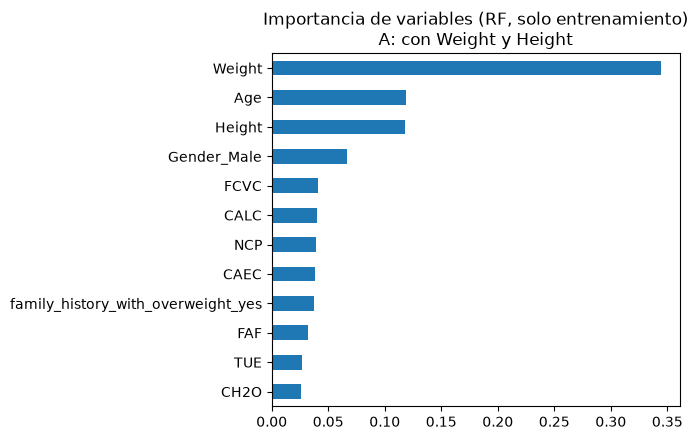

,Configuración,Columnas,F1 macro (CV),Desv.
0,Sin selección,20,0.9364,0.0115
1,Conservadora (umbral 0.5 x mediana),15,0.9242,0.0137
2,Agresiva (umbral mediana),10,0.9365,0.0070


Configuración elegida: Agresiva (umbral mediana)


KNN  | mejor F1 macro (CV): 0.8444 | {'n_neighbors': 4, 'weights': 'distance', 'p': 1}


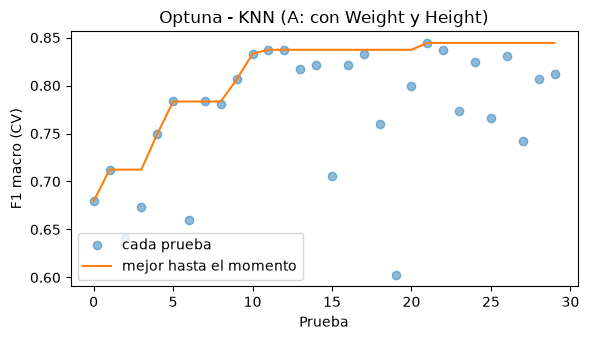

XGB  | mejor F1 macro (CV): 0.9621 | {'n_estimators': 350, 'max_depth': 5, 'learning_rate': 0.08988867164246662, 'subsample': 0.644141711623644, 'colsample_bytree': 0.9081039528761908, 'min_child_weight': 1, 'reg_lambda': 0.2705545508298562}


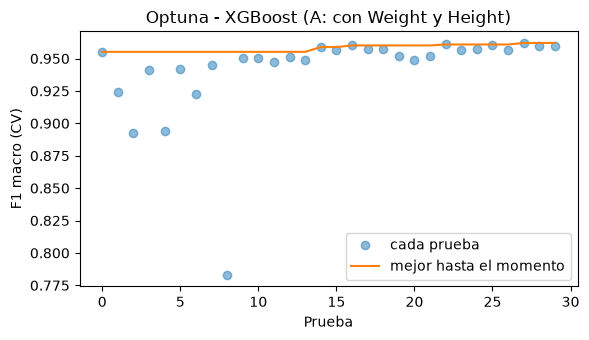

Importancia de hiperparámetros (XGBoost): {'colsample_bytree': 0.492, 'subsample': 0.154, 'learning_rate': 0.121, 'min_child_weight': 0.084, 'max_depth': 0.082, 'reg_lambda': 0.042, 'n_estimators': 0.025}


,Escenario,Modelo,Origen,F1 macro (CV),Accuracy (prueba),F1 macro (prueba),Recall macro (prueba),% errores a clase vecina
0,A: con Weight y Height,Regresión logística,Autores,0.8625,0.8684,0.8616,0.8640,98.2
1,A: con Weight y Height,Árbol de decisión,Autores,0.9235,0.9474,0.9468,0.9465,95.5
2,A: con Weight y Height,Naive Bayes,Autores,0.6072,0.6244,0.5992,0.6239,69.4
3,A: con Weight y Height,Random Forest,Autores,0.9396,0.9330,0.9308,0.9297,92.9
4,A: con Weight y Height,SVM,Autores,0.8793,0.8900,0.8864,0.8864,84.8
5,A: con Weight y Height,MLP,Autores,0.9446,0.9522,0.9508,0.9502,100.0
6,A: con Weight y Height,KNN (sin ajustar),Propuesto,0.7616,0.7679,0.7591,0.7630,63.9
7,A: con Weight y Height,XGBoost (sin ajustar),Propuesto,0.9596,0.9569,0.9566,0.9555,94.4
8,A: con Weight y Height,KNN (Optuna),Propuesto,0.8463,0.8421,0.8315,0.8363,66.7
9,A: con Weight y Height,XGBoost (Optuna),Propuesto,0.9612,0.9522,0.9520,0.9507,95.0


In [ ]:
ESC_A = "A: con Weight y Height"
estudios_A = ejecutar_escenario(ESC_A, excluir=[])
display(pd.DataFrame([r for r in resultados if r["Escenario"] == ESC_A]))

**Interpretación:** en el escenario A los modelos de árboles y la MLP superan 0.93 de F1 macro y la mayoría de sus errores son con una clase vecina, es decir, en los bordes del IMC. Esto se explica por la fuga de información (el modelo recalcula el IMC) y por los datos sintéticos. Como los resultados ya están cerca del techo, los modelos propuestos tienen poco margen para mejorar.

### Escenario B: sin `Weight` ni `Height` (solo hábitos y datos demográficos)

ESCENARIO B: sin Weight ni Height
Numéricas usadas: ['Age', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
Eliminadas por correlación > 0.90: ninguna


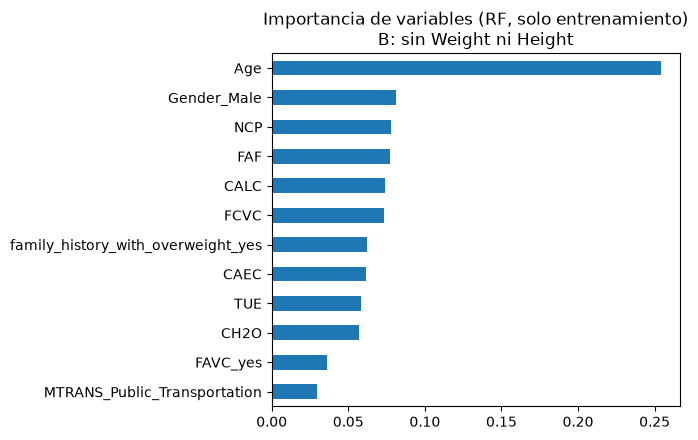

,Configuración,Columnas,F1 macro (CV),Desv.
0,Sin selección,18,0.7916,0.0348
1,Conservadora (umbral 0.5 x mediana),12,0.7872,0.0230
2,Agresiva (umbral mediana),9,0.7413,0.0150


Configuración elegida: Sin selección


KNN  | mejor F1 macro (CV): 0.7117 | {'n_neighbors': 4, 'weights': 'distance', 'p': 1}


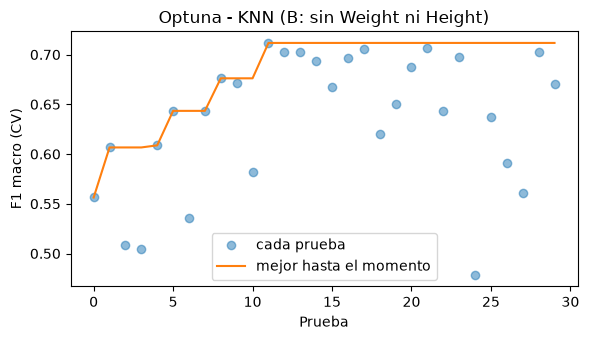

XGB  | mejor F1 macro (CV): 0.7987 | {'n_estimators': 200, 'max_depth': 10, 'learning_rate': 0.08618772064823761, 'subsample': 0.6714157980362956, 'colsample_bytree': 0.8121862290625653, 'min_child_weight': 1, 'reg_lambda': 0.019782686933492465}


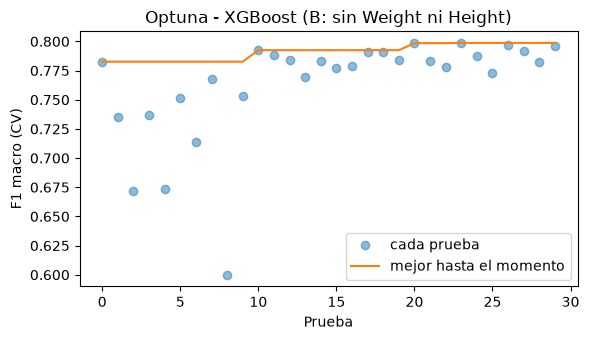

Importancia de hiperparámetros (XGBoost): {'subsample': 0.248, 'colsample_bytree': 0.244, 'max_depth': 0.224, 'min_child_weight': 0.148, 'reg_lambda': 0.088, 'learning_rate': 0.045, 'n_estimators': 0.003}


,Escenario,Modelo,Origen,F1 macro (CV),Accuracy (prueba),F1 macro (prueba),Recall macro (prueba),% errores a clase vecina
0,B: sin Weight ni Height,Regresión logística,Autores,0.5436,0.5789,0.5509,0.5670,47.2
1,B: sin Weight ni Height,Árbol de decisión,Autores,0.6879,0.6651,0.6635,0.6632,41.4
2,B: sin Weight ni Height,Naive Bayes,Autores,0.3192,0.3947,0.3173,0.3979,56.1
3,B: sin Weight ni Height,Random Forest,Autores,0.7898,0.7727,0.7663,0.7697,44.2
4,B: sin Weight ni Height,SVM,Autores,0.7218,0.7440,0.7382,0.7414,47.7
5,B: sin Weight ni Height,MLP,Autores,0.7353,0.7273,0.7216,0.7250,43.9
6,B: sin Weight ni Height,KNN (sin ajustar),Propuesto,0.6655,0.6794,0.6661,0.6748,38.8
7,B: sin Weight ni Height,XGBoost (sin ajustar),Propuesto,0.8088,0.7847,0.7794,0.7813,45.6
8,B: sin Weight ni Height,KNN (Optuna),Propuesto,0.7188,0.7153,0.7024,0.7105,36.1
9,B: sin Weight ni Height,XGBoost (Optuna),Propuesto,0.8077,0.7799,0.7726,0.7747,42.4


In [ ]:
ESC_B = "B: sin Weight ni Height"
estudios_B = ejecutar_escenario(ESC_B, excluir=["Weight", "Height"])
display(pd.DataFrame([r for r in resultados if r["Escenario"] == ESC_B]))

**Interpretación:** al quitar peso y altura el F1 macro baja en todos los modelos, aunque sigue muy por encima del azar (1/7 ≈ 0.14), así que los hábitos sí tienen poder predictivo. La edad pasa a ser la variable más importante, seguida del género, el número de comidas, la actividad física, el alcohol y el consumo de verduras. Los que más pierden son la regresión logística (−0.31), el árbol de decisión (−0.28) y Naive Bayes (−0.28).

## 7. Comparación final de todos los modelos (conjunto de prueba)

In [ ]:
tabla_final = pd.DataFrame(resultados)
tabla_final.to_csv("resultados_obesidad.csv", index=False)

for esc in [ESC_A, ESC_B]:
    t = tabla_final[tabla_final["Escenario"] == esc].sort_values("F1 macro (prueba)", ascending=False).reset_index(drop=True)
    print("\n" + esc)
    display(t.drop(columns="Escenario"))

# Efecto de quitar Weight y Height, modelo por modelo
comparacion = tabla_final.pivot(index="Modelo", columns="Escenario", values="F1 macro (prueba)")
comparacion["Diferencia (B - A)"] = (comparacion[ESC_B] - comparacion[ESC_A]).round(4)
display(comparacion.sort_values(ESC_B, ascending=False))


A: con Weight y Height


,Modelo,Origen,F1 macro (CV),Accuracy (prueba),F1 macro (prueba),Recall macro (prueba),% errores a clase vecina
0,XGBoost (sin ajustar),Propuesto,0.9596,0.9569,0.9566,0.9555,94.4
1,XGBoost (Optuna),Propuesto,0.9612,0.9522,0.9520,0.9507,95.0
2,MLP,Autores,0.9446,0.9522,0.9508,0.9502,100.0
3,Árbol de decisión,Autores,0.9235,0.9474,0.9468,0.9465,95.5
4,Random Forest,Autores,0.9396,0.9330,0.9308,0.9297,92.9
5,SVM,Autores,0.8793,0.8900,0.8864,0.8864,84.8
6,Regresión logística,Autores,0.8625,0.8684,0.8616,0.8640,98.2
7,KNN (Optuna),Propuesto,0.8463,0.8421,0.8315,0.8363,66.7
8,KNN (sin ajustar),Propuesto,0.7616,0.7679,0.7591,0.7630,63.9
9,Naive Bayes,Autores,0.6072,0.6244,0.5992,0.6239,69.4



B: sin Weight ni Height


,Modelo,Origen,F1 macro (CV),Accuracy (prueba),F1 macro (prueba),Recall macro (prueba),% errores a clase vecina
0,XGBoost (sin ajustar),Propuesto,0.8088,0.7847,0.7794,0.7813,45.6
1,XGBoost (Optuna),Propuesto,0.8077,0.7799,0.7726,0.7747,42.4
2,Random Forest,Autores,0.7898,0.7727,0.7663,0.7697,44.2
3,SVM,Autores,0.7218,0.7440,0.7382,0.7414,47.7
4,MLP,Autores,0.7353,0.7273,0.7216,0.7250,43.9
5,KNN (Optuna),Propuesto,0.7188,0.7153,0.7024,0.7105,36.1
6,KNN (sin ajustar),Propuesto,0.6655,0.6794,0.6661,0.6748,38.8
7,Árbol de decisión,Autores,0.6879,0.6651,0.6635,0.6632,41.4
8,Regresión logística,Autores,0.5436,0.5789,0.5509,0.5670,47.2
9,Naive Bayes,Autores,0.3192,0.3947,0.3173,0.3979,56.1


Escenario,A: con Weight y Height,B: sin Weight ni Height,Diferencia (B - A)
Modelo,,,
XGBoost (sin ajustar),0.9566,0.7794,-0.1772
XGBoost (Optuna),0.9520,0.7726,-0.1794
Random Forest,0.9308,0.7663,-0.1645
SVM,0.8864,0.7382,-0.1482
MLP,0.9508,0.7216,-0.2292
KNN (Optuna),0.8315,0.7024,-0.1291
KNN (sin ajustar),0.7591,0.6661,-0.0930
Árbol de decisión,0.9468,0.6635,-0.2833
Regresión logística,0.8616,0.5509,-0.3107


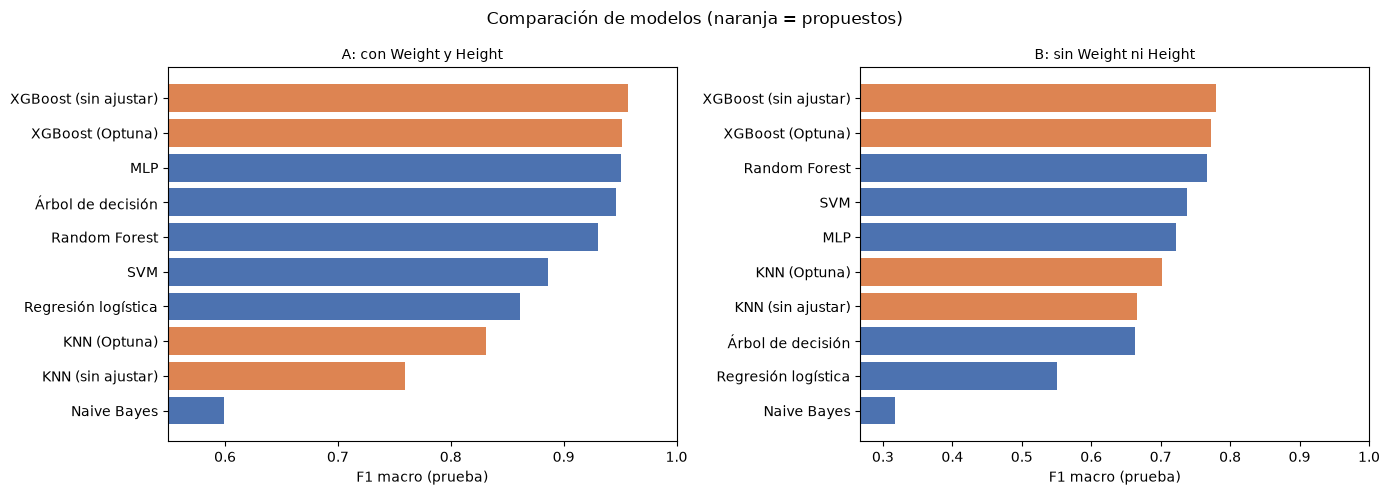

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=False)
for ax, esc in zip(axes, [ESC_A, ESC_B]):
    t = tabla_final[tabla_final["Escenario"] == esc].sort_values("F1 macro (prueba)")
    colores = ["#dd8452" if o == "Propuesto" else "#4c72b0" for o in t["Origen"]]
    ax.barh(t["Modelo"], t["F1 macro (prueba)"], color=colores)
    ax.set_title(esc, fontsize=10); ax.set_xlabel("F1 macro (prueba)")
    ax.set_xlim(max(0, t["F1 macro (prueba)"].min() - 0.05), 1.0)
fig.suptitle("Comparación de modelos (naranja = propuestos)")
plt.tight_layout(); plt.show()


A: con Weight y Height -> mejor modelo: XGBoost (sin ajustar)

                     precision    recall  f1-score   support

Insufficient_Weight       0.98      1.00      0.99        53
      Normal_Weight       0.96      0.93      0.95        57
 Overweight_Level_I       0.94      0.89      0.92        55
Overweight_Level_II       0.93      0.93      0.93        58
     Obesity_Type_I       0.91      0.99      0.95        70
    Obesity_Type_II       0.98      0.97      0.97        60
   Obesity_Type_III       1.00      0.98      0.99        65

           accuracy                           0.96       418
          macro avg       0.96      0.96      0.96       418
       weighted avg       0.96      0.96      0.96       418



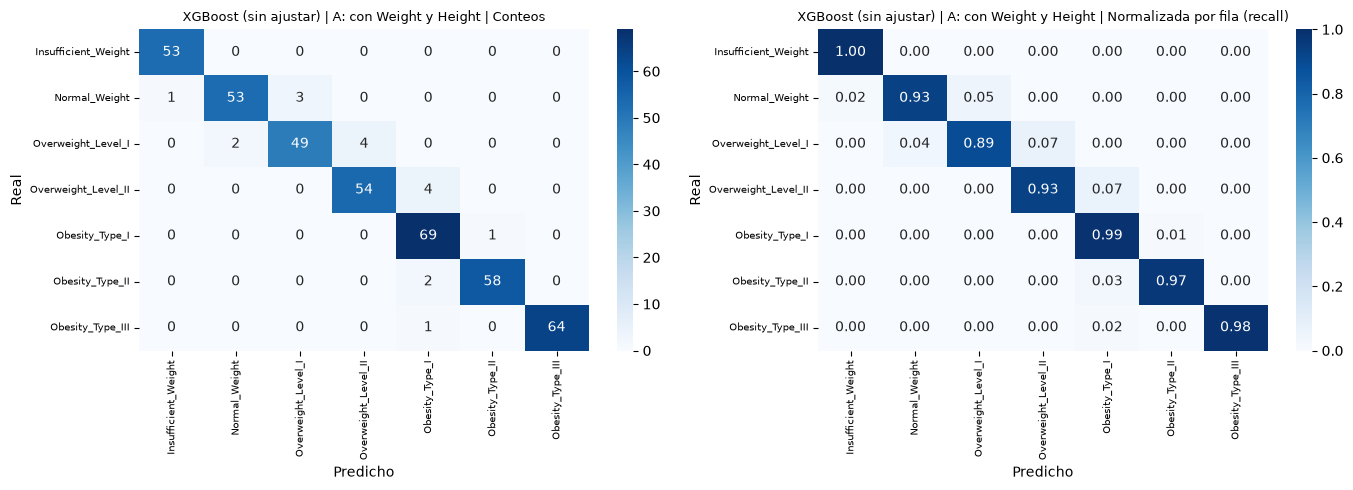


B: sin Weight ni Height -> mejor modelo: XGBoost (sin ajustar)

                     precision    recall  f1-score   support

Insufficient_Weight       0.80      0.89      0.84        53
      Normal_Weight       0.62      0.58      0.60        57
 Overweight_Level_I       0.73      0.75      0.74        55
Overweight_Level_II       0.67      0.66      0.66        58
     Obesity_Type_I       0.81      0.80      0.81        70
    Obesity_Type_II       0.82      0.83      0.83        60
   Obesity_Type_III       1.00      0.97      0.98        65

           accuracy                           0.78       418
          macro avg       0.78      0.78      0.78       418
       weighted avg       0.78      0.78      0.78       418



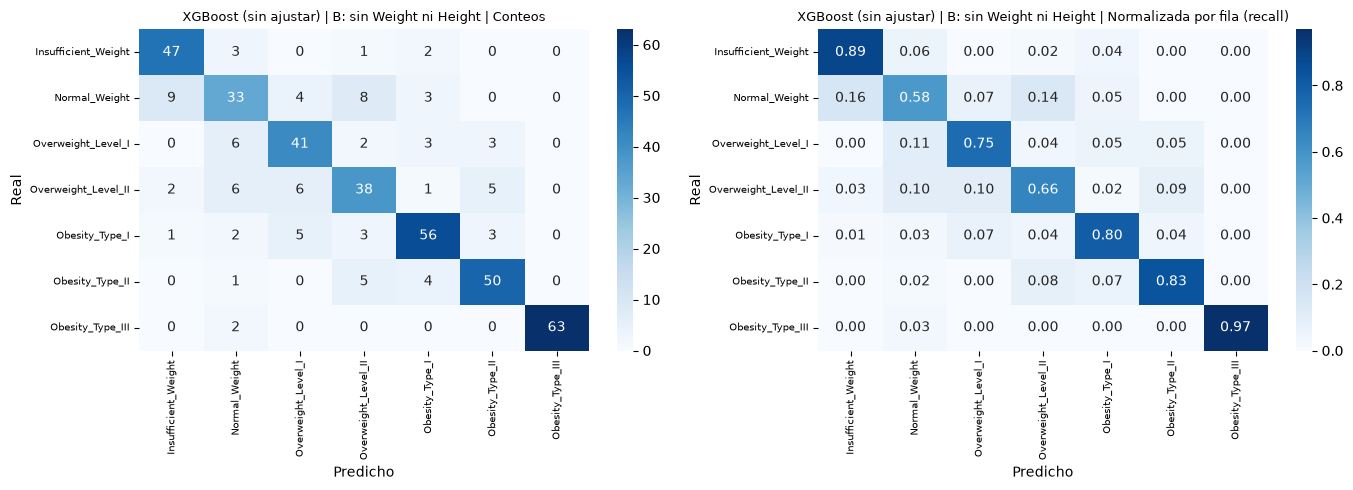


A: con Weight y Height - XGBoost (Optuna)

                     precision    recall  f1-score   support

Insufficient_Weight       0.98      1.00      0.99        53
      Normal_Weight       0.98      0.91      0.95        57
 Overweight_Level_I       0.92      0.89      0.91        55
Overweight_Level_II       0.92      0.93      0.92        58
     Obesity_Type_I       0.90      0.99      0.94        70
    Obesity_Type_II       0.98      0.95      0.97        60
   Obesity_Type_III       1.00      0.98      0.99        65

           accuracy                           0.95       418
          macro avg       0.95      0.95      0.95       418
       weighted avg       0.95      0.95      0.95       418




B: sin Weight ni Height - XGBoost (Optuna)

                     precision    recall  f1-score   support

Insufficient_Weight       0.77      0.89      0.82        53
      Normal_Weight       0.60      0.58      0.59        57
 Overweight_Level_I       0.69      0.69      0.69        55
Overweight_Level_II       0.67      0.62      0.64        58
     Obesity_Type_I       0.84      0.84      0.84        70
    Obesity_Type_II       0.83      0.83      0.83        60
   Obesity_Type_III       1.00      0.97      0.98        65

           accuracy                           0.78       418
          macro avg       0.77      0.77      0.77       418
       weighted avg       0.78      0.78      0.78       418



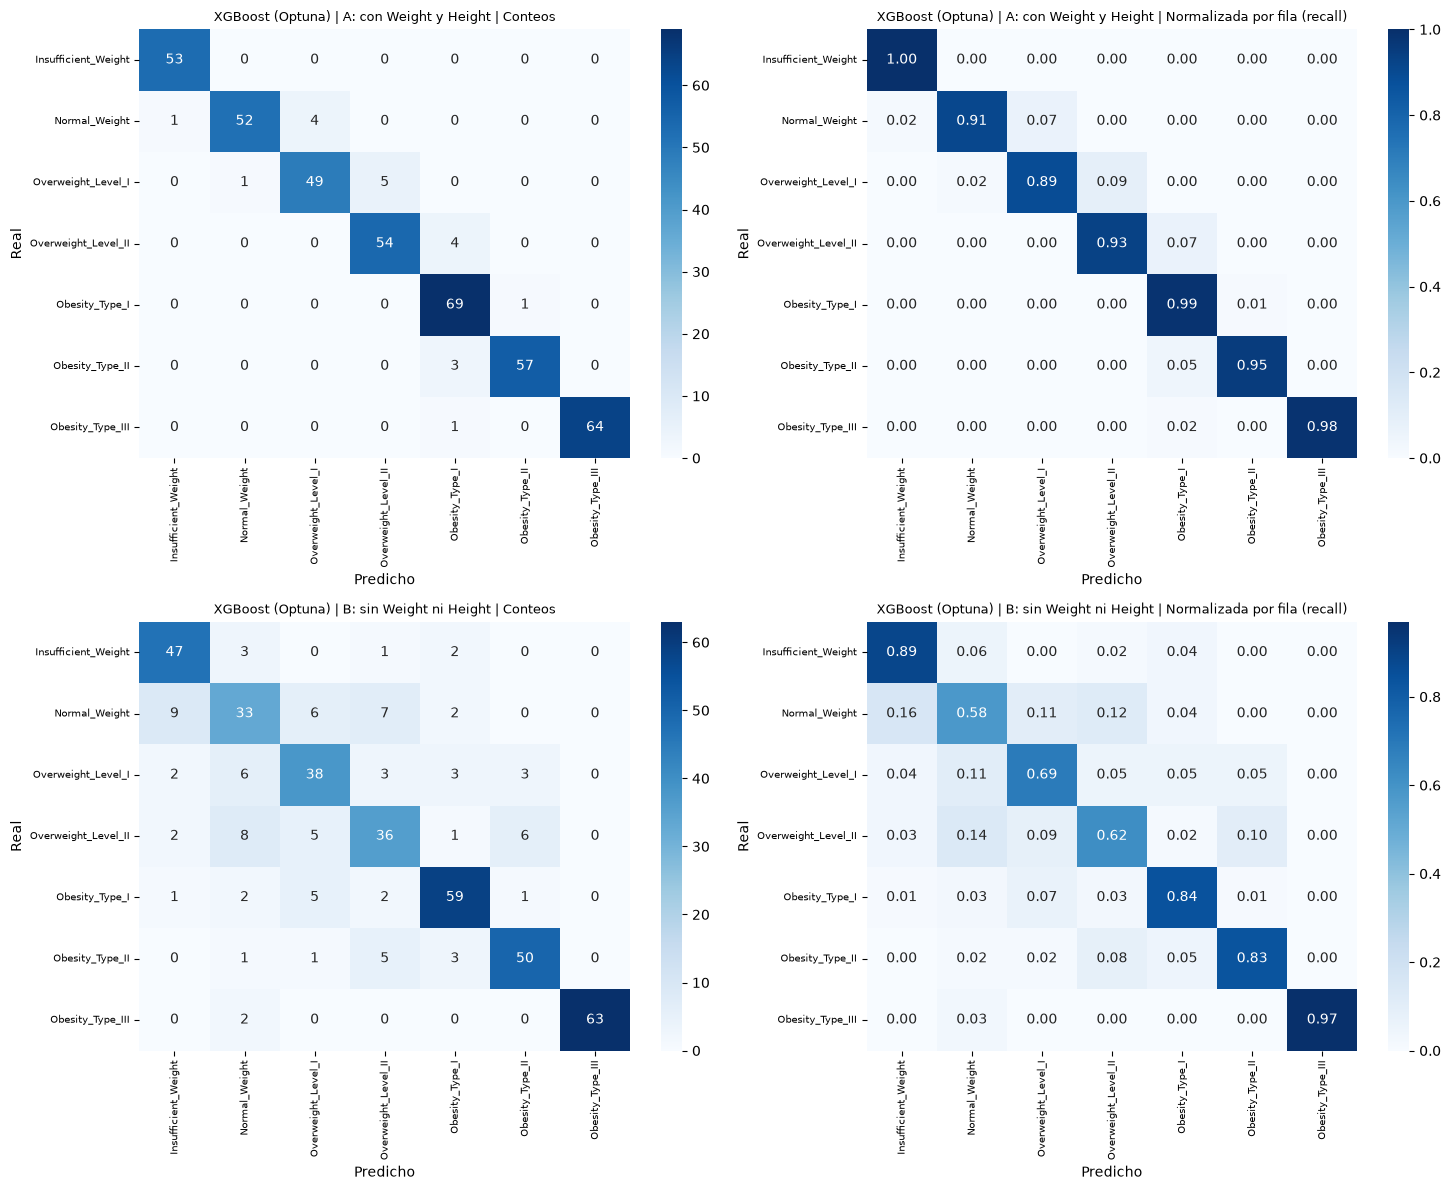

In [ ]:
for esc in [ESC_A, ESC_B]:
    t = tabla_final[tabla_final["Escenario"] == esc].sort_values("F1 macro (prueba)", ascending=False)
    mejor = t.iloc[0]["Modelo"]
    print(f"\n{esc} -> mejor modelo: {mejor}\n")
    print(classification_report(y_test, predicciones[(esc, mejor)], target_names=CLASES, zero_division=0))

    cm = confusion_matrix(y_test, predicciones[(esc, mejor)])
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, M, tt, fmt in [(axes[0], cm, "Conteos", "d"), (axes[1], cm_norm, "Normalizada por fila (recall)", ".2f")]:
        sns.heatmap(M, annot=True, fmt=fmt, cmap="Blues", xticklabels=CLASES, yticklabels=CLASES, ax=ax)
        ax.set_title(f"{mejor} | {esc} | {tt}", fontsize=9); ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
        ax.tick_params(axis="both", labelsize=7)
    plt.tight_layout(); plt.show()


# Matriz de confusión de XGBoost (Optuna) en ambos escenarios
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for fila, esc in enumerate([ESC_A, ESC_B]):
    pred_xgb = predicciones[(esc, "XGBoost (Optuna)")]
    cm = confusion_matrix(y_test, pred_xgb)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    for col, (M, titulo, fmt) in enumerate([(cm, "Conteos", "d"),
                                            (cm_norm, "Normalizada por fila (recall)", ".2f")]):
        sns.heatmap(M, annot=True, fmt=fmt, cmap="Blues", xticklabels=CLASES, yticklabels=CLASES,
                    ax=axes[fila, col])
        axes[fila, col].set_title(f"XGBoost (Optuna) | {esc} | {titulo}", fontsize=9)
        axes[fila, col].set_xlabel("Predicho"); axes[fila, col].set_ylabel("Real")
        axes[fila, col].tick_params(axis="both", labelsize=7)
    print(f"\n{esc} - XGBoost (Optuna)\n")
    print(classification_report(y_test, pred_xgb, target_names=CLASES, zero_division=0))
plt.tight_layout(); plt.show()

**Interpretación:** en ambos escenarios el mejor modelo es XGBoost sin ajustar. En el escenario A obtiene un F1 macro de 0.9566, seguido de XGBoost con Optuna (0.9520) y la MLP (0.9508). En el escenario B obtiene 0.7794, seguido de XGBoost con Optuna (0.7726) y Random Forest (0.7663). Optuna mejoró claramente a KNN, pero no a XGBoost, cuyos valores por defecto ya eran buenos. Las diferencias entre los mejores modelos son de pocas centésimas, así que deben leerse como empates si son menores que la desviación entre particiones. En el escenario A casi todos los errores son con una clase vecina; en el B, alrededor de la mitad.

**Validez:** como gran parte de los datos es sintético (SMOTE interpola entre registros reales), el conjunto de prueba contiene casi-copias de datos de entrenamiento, así que las métricas pueden estar infladas. Esto se discute en el informe junto con las repercusiones éticas y sociales.